# Koch snowflake

Take a line, push its middle third out into a triangle, and do the same to each of the four new
lines, again and again. Every round makes the outline a third longer, so in the limit it is
infinitely long, while the area inside stays finite. Five filled snowflakes are stacked here
like layers of a crystal, smaller and lighter toward the center.

In [1]:
import math

from common import mix
from nbturtle import render

OUTER = (0.10, 0.25, 0.45)
INNER = (0.85, 0.97, 1.0)
LAYERS = 5

## A curve that calls itself

`koch(t, length, depth)` draws a straight line when `depth` is 0. Otherwise it draws four Koch
curves a third as long, turning +60°, −120° and +60° between them. Depths 0 to 4:

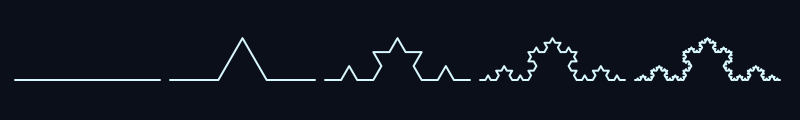

In [2]:
def koch(t, length, depth):
    if depth == 0:
        t.forward(length)
        return
    for turn in (60, -120, 60, 0):
        koch(t, length / 3, depth - 1)
        t.left(turn)


def depths(t):
    t.pensize(2)
    t.pencolor(INNER)
    for depth in range(5):
        t.goto(-385 + depth * 155, -20)
        t.setheading(0)
        t.pendown()
        koch(t, 145, depth)
        t.penup()


render(depths, 800, 120)

## Three curves make a snowflake

The turtle walks a triangle clockwise, turning right 120° at each corner. Walking clockwise, its
left side is the outside, and the curve bumps out to the left, so the bumps point outward.
`begin_fill` and `end_fill` fill everything the turtle walked around.

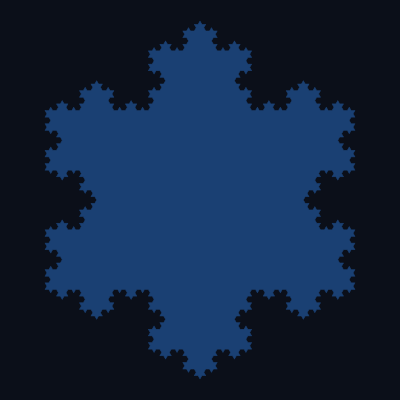

In [3]:
def snowflake(t, side, depth, color):
    # start at the top-left vertex so the bumps point outward
    t.goto(-side / 2, side * math.sqrt(3) / 6)
    t.setheading(0)
    t.color(color, color)
    t.pendown()
    t.begin_fill()
    for _ in range(3):
        koch(t, side, depth)
        t.right(120)
    t.end_fill()
    t.penup()


render(lambda t: snowflake(t, 620, 4, OUTER), dpi=36)

## Five layers

Each layer is 78 % the size of the one below it, and `mix` blends its color from deep blue to ice.

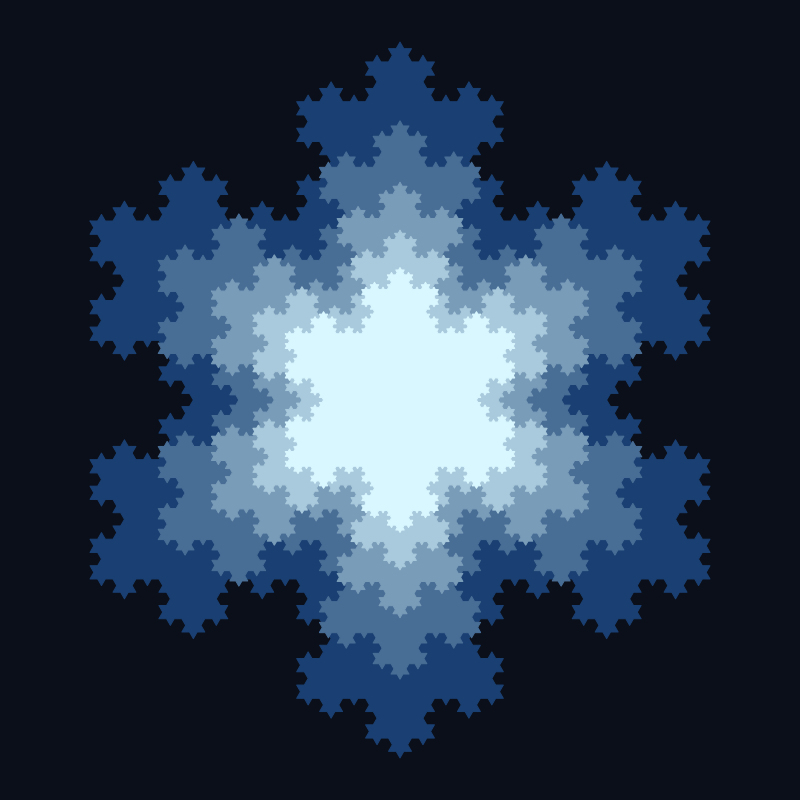

In [4]:
def draw(t):
    for i in range(LAYERS):
        snowflake(t, 620 * 0.78 ** i, 4, mix(OUTER, INNER, i / (LAYERS - 1)))


render(draw)

## Try

- Depth 1 gives a six-pointed star; depth 6 is about as fine as the screen can show.
- `LAYERS = 9` with `0.85 ** i` for thinner layers.